# Bird biodiversity in Martinique, 2014–2025

**Authors:** Mykhailo Mas, Adam Nolan.

Preparation and descriptive analysis. Run all cells, then run Notebook 2 for confidence intervals, trends and selected species.

A row is a detection entry; a point survey is `(route, date, visit, point)`. Counts describe recorded detections, not population size. The source workbook is never modified.

| Assignment requirement | This notebook |
|---|---|
| Data structure, identifiers, period | Sections 1–2 |
| Missingness, anomalies, cleaning | Sections 1–3 |
| Counts, observer effort, weather and spatial coverage | Sections 4–5 |
| Three annual indicators | Section 5 |
| Sensitivity to preparation and coverage | Section 6 |
| Reusable tables and standard figures | Section 7 |

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# The same plain plotting defaults in both notebooks.
plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "savefig.transparent": False,
    "savefig.dpi": 180, "axes.grid": True, "grid.alpha": 0.25,
})

ROOT = Path.cwd()
if not (ROOT / "data/raw").exists():
    ROOT = ROOT.parent

for folder in ["data/processed", "results", "figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

FIGURES = ROOT / "figures"

source = ROOT / "data/raw/Observations 2012-2025.xlsx"
sheets = pd.read_excel(source, sheet_name=None, header=None)

survey_key = ["route_key", "date", "visit", "point"]
visit_key = ["route_key", "date", "visit"]
metrics = ["richness", "recorded_abundance", "shannon"]
metric_labels = {"richness": "Species per survey", "recorded_abundance": "Detections per survey",
                 "shannon": "Shannon (nats)"}
years = range(2014, 2026)


def normalize(values):
    values = values.astype("string").str.strip()
    values = values.str.replace(r"\s+", " ", regex=True)
    return values.str.casefold()

In [2]:
sheet_structure = pd.DataFrame([
    {"sheet": name, "rows_including_headers": len(table), "columns": table.shape[1]}
    for name, table in sheets.items()
])
display(sheet_structure)

,sheet,rows_including_headers,columns
0,ESPECES,87,5
1,GPS-MILIEU,652,8
2,NOM FRANÇAIS,114498,26


## 1. Load and validate records

The observation sheet has three header rows. Use the non-flight total (`selected_count`); adding it to the eight detection bins would double count birds. Remove exact copies using all original fields before dropping names and comments. Normalize labels and repair the known route spelling variant.

In [3]:
columns = [
    "observer", "department", "route", "date", "visit",
    "cloud", "rain", "wind", "visibility", "point", "start_time", "species",
    "auditory_25", "visual_25", "auditory_50", "visual_50",
    "auditory_100", "visual_100", "auditory_far", "visual_far", "flight",
    "auditory_total", "visual_total", "selected_count", "total_with_flight", "comment",
]
raw = sheets["NOM FRANÇAIS"].iloc[3:].copy()
assert raw.shape[1] == len(columns)
raw.columns = columns
nonempty = raw.dropna(how="all")
obs = nonempty.drop_duplicates().copy()
obs["source_row"] = obs.index + 1

for field in ["route", "species", "observer"]:
    obs[field + "_key"] = normalize(obs[field]).replace("", pd.NA)
obs["route_key"] = obs["route_key"].replace({"desmarinière": "desmarinières"})
obs["date"] = pd.to_datetime(obs["date"], errors="coerce")
obs["year"] = obs["date"].dt.year
source_dates = obs["date"].agg(["min", "max"])

# Count blank strings as missing; do not replace missing counts with zero.
missingness = raw.replace(r"^\s*$", np.nan, regex=True).isna().sum().to_frame("missing_rows")
missingness["percent"] = 100 * missingness["missing_rows"] / len(raw)
display(missingness.round(2))

,missing_rows,percent
observer,0,0.00
department,2,0.00
route,0,0.00
date,0,0.00
visit,0,0.00
cloud,2,0.00
rain,1,0.00
wind,17,0.01
visibility,1,0.00
point,0,0.00


In [4]:
numeric_columns = ["visit", "point"] + columns[12:25]
original_numbers = obs[numeric_columns].copy()
converted = original_numbers.apply(pd.to_numeric, errors="coerce")
nonblank = original_numbers.astype("string").apply(lambda s: s.str.strip().ne("").fillna(False))
malformed = nonblank & converted.isna()
obs[numeric_columns] = converted

valid_key = (
        obs[survey_key].notna().all(axis=1)
        & obs["point"].between(1, 10) & obs["point"].mod(1).eq(0)
        & obs["visit"].isin([1, 2])
)
in_period = obs["year"].between(2014, 2025)
cleaning_audit = pd.Series({
    "source_rows": len(raw),
    "empty_rows_removed": len(raw) - len(nonempty),
    "exact_copies_removed": len(nonempty) - len(obs),
    "invalid_survey_key_removed": int((~valid_key).sum()),
    "outside_period_removed_after_key_check": int((valid_key & ~in_period).sum()),
    "retained_rows": int((valid_key & in_period).sum()),
}, name="rows").to_frame()
obs = obs.loc[valid_key & in_period].copy()
obs[["year", "visit", "point"]] = obs[["year", "visit", "point"]].astype(int)
assert len(obs) + cleaning_audit.iloc[1:5, 0].sum() == len(raw)
display(cleaning_audit)
print(f"Observed dates before period filtering: {source_dates['min'].date()} to {source_dates['max'].date()}")

,rows
source_rows,114495
empty_rows_removed,0
exact_copies_removed,2243
invalid_survey_key_removed,0
outside_period_removed_after_key_check,0
retained_rows,112252


Observed dates before period filtering: 2014-03-29 to 2025-07-03


## 2. Join species and point references

Both joins are many-to-one. Habitat is matched by route and point. Repair the reference typos `Pigeon à coup rouge` and `SIPI`. Unmatched species labels are listed for review; a missing reference alone does not prove that a label is an unidentified group.

In [5]:
species = sheets["ESPECES"].iloc[:, 2:5].drop_duplicates().copy()
species.columns = ["reference_species", "scientific_name", "status"]
species["species_key"] = normalize(species["reference_species"])
species["species_key"] = species["species_key"].replace({
    "pigeon à coup rouge": "pigeon à cou rouge",
})

habitat = sheets["GPS-MILIEU"].iloc[2:, 2:8].copy()
habitat.columns = [
    "reference_route", "x_utm20", "y_utm20",
    "habitat", "route_code", "point_code",
]
habitat["route_key"] = normalize(habitat["reference_route"])

point_codes = habitat["point_code"].replace({"SIPI": "S1P1"})
point_numbers = point_codes.str.extract(r"P(\d+)$")[0]
habitat["point"] = point_numbers.astype(int)

obs = obs.merge(
    species,
    on="species_key",
    how="left",
    validate="many_to_one",
)
obs = obs.merge(
    habitat,
    on=["route_key", "point"],
    how="left",
    validate="many_to_one",
)

In [6]:
reference_audit = pd.Series({
    "rows_without_species_reference": obs["scientific_name"].isna().sum(),
    "rows_without_habitat": obs["habitat"].isna().sum(),
}, name="rows").to_frame()
unmatched_species = (
    obs.loc[obs["scientific_name"].isna(), "species_key"]
    .value_counts(dropna=False).rename_axis("species_key").to_frame("rows")
)
display(reference_audit)
display(unmatched_species)

,rows
rows_without_species_reference,1168
rows_without_habitat,0


,rows
species_key,
trochilidae,989
estrildidae,90
apodidae,21
hirundinidae,16
columbidae,10
limicole,8
bécasseau semipalmé,6
martinet,5
lonchura sp.,4


## 3. Validate counts and calculate indicators

Missing, negative, fractional or conflicting counts invalidate the whole survey. Blank detail bins count as zero only for checking the supplied total. Unidentified positive detections invalidate richness and Shannon, but contribute to abundance. `RAS` means zero detections.

Richness measures the number of detected species; abundance measures total recorded detections; Shannon combines richness and evenness. For counts $n_s$, $N=\sum_s n_s$, $S=\sum_s 1(n_s>0)$ and $H=-\sum_s(n_s/N)\log(n_s/N)$. Shannon is undefined when $N=0$.

In [7]:
detail_columns = columns[12:20]
subtotal_columns = ["auditory_total", "visual_total"]
components = obs[detail_columns + subtotal_columns]
bad_component = ((components < 0) | (components.mod(1).ne(0) & components.notna())).any(axis=1)
selected_count = obs["selected_count"]
bad_total = selected_count.isna() | (selected_count < 0) | selected_count.mod(1).ne(0)
bad_detail = ~np.isclose(selected_count, obs[detail_columns].sum(axis=1))
complete_subtotals = obs[subtotal_columns].notna().all(axis=1)
bad_subtotal = complete_subtotals & ~np.isclose(selected_count, obs[subtotal_columns].sum(axis=1))
checked_columns = detail_columns + subtotal_columns + ["selected_count"]
bad_source_rows = malformed.index[malformed[checked_columns].any(axis=1)] + 1
obs["count_problem"] = (
        bad_total | bad_component | bad_detail | bad_subtotal
        | obs["source_row"].isin(bad_source_rows)
)

unresolved_taxa = {
    "trochilidae", "estrildidae", "apodidae", "hirundinidae", "columbidae",
    "limicole", "martinet", "mimidae", "lonchura sp.", "sterne sp",
    "capucin sp", "fauconidae", "gallinacées", "moqueur sp.", "anatidae",
    "egretta sp.", "falconidé", "héron ?",
}
obs["unresolved_positive"] = (
        (obs["species_key"].isin(unresolved_taxa) | obs["species_key"].isna())
        & selected_count.gt(0)
)
zero_marker = obs["species_key"].eq("ras").fillna(False)
assert obs.loc[zero_marker, "selected_count"].eq(0).all()
display(obs.loc[obs["count_problem"], ["source_row", "species", "selected_count"]].head(10))

,source_row,species,selected_count
5081,5094,Héron vert,0.0
5082,5095,Quiscale merle,0.0
5083,5096,Sucrier à ventre jaune,0.0
5084,5097,Elénie siffleuse,0.0
5085,5098,Merle à lunettes,0.0
5086,5099,Saltator gros-bec,0.0
5087,5100,Saltator gros-bec,0.0
5088,5101,Elénie siffleuse,0.0
5089,5102,Sucrier à ventre jaune,0.0
5090,5103,Merle à lunettes,0.0


In [8]:
# One row per point survey, with its quality flags.
points = obs.groupby(survey_key).agg(
    year=("year", "first"),
    habitat=("habitat", "first"),
    count_problem=("count_problem", "any"),
    unresolved_positive=("unresolved_positive", "any"),
    observer_labels=("observer_key", "nunique"),
    start_times=("start_time", "nunique"),
)

# Sum detection entries for each species within each survey.
birds = obs.loc[~zero_marker]
species_counts = birds.groupby(survey_key + ["species_key"], dropna=False)
counts = species_counts["selected_count"].sum().unstack(fill_value=0)
counts = counts.reindex(points.index, fill_value=0)

repeated_species = obs.duplicated(survey_key + ["species_key"], keep=False)
survey_groups = [obs[field] for field in survey_key]
points["repeated_species"] = repeated_species.groupby(survey_groups).any()
points["metadata_conflict"] = (
        (points["observer_labels"] > 1)
        | (points["start_times"] > 1)
)

In [9]:
# Abundance counts detections; richness counts species with positive counts.
points["recorded_abundance"] = counts.sum(axis=1)
points["richness"] = (counts > 0).sum(axis=1)

# Shannon: H = -sum(p * log(p)), using only positive proportions.
abundance = points["recorded_abundance"].replace(0, np.nan)
proportions = counts.div(abundance, axis=0)
positive_proportions = proportions.where(proportions > 0)
shannon_terms = proportions * np.log(positive_proportions)
points["shannon"] = -shannon_terms.sum(axis=1, min_count=1)

# Invalid counts affect every indicator; unidentified birds affect diversity.
points.loc[points["count_problem"], metrics] = np.nan
points.loc[points["unresolved_positive"], ["richness", "shannon"]] = np.nan

points = points.reset_index()
display(points[metrics].describe())

,richness,recorded_abundance,shannon
count,13077.000000,14076.000000,13074.000000
mean,7.759043,17.199844,1.810549
std,2.667252,10.881662,0.390437
min,0.000000,0.000000,-0.000000
25%,6.000000,10.000000,1.581094
50%,8.000000,15.000000,1.863680
75%,10.000000,22.000000,2.084430
max,18.000000,210.000000,2.685771


In [10]:
assert not points.duplicated(survey_key).any()
assert points.loc[points["count_problem"], metrics].isna().all().all()
assert points.loc[points["unresolved_positive"], ["richness", "shannon"]].isna().all().all()
assert points["recorded_abundance"].dropna().ge(0).all()
assert points["richness"].dropna().ge(0).all()
assert points["shannon"].dropna().ge(-1e-12).all()

quality_by_year = points.groupby("year")[[
    "count_problem", "unresolved_positive", "metadata_conflict", "repeated_species"
]].sum()
quality_by_year["surveys"] = points.groupby("year").size()
display(quality_by_year)
print(
    "Flags can overlap. Conflicting observers/times and repeated species are retained in the baseline; Section 6 tests their exclusion.")

,count_problem,unresolved_positive,metadata_conflict,repeated_species,surveys
year,,,,,
2014,39,85,8,27,779
2015,1,159,15,26,1060
2016,7,161,4,22,1162
2017,4,126,7,16,1169
2018,4,99,12,22,1265
2019,6,84,10,22,1247
2020,16,11,11,29,1158
2021,4,35,7,27,1256
2022,4,12,13,39,1259


Flags can overlap. Conflicting observers/times and repeated species are retained in the baseline; Section 6 tests their exclusion.


,route_key,date,visit,point,year,habitat,richness,recorded_abundance,shannon
7424,ilets du robert,2021-05-07,1,4,2021,Forêt sèche,9.0,210.0,0.941427
7499,ilets du robert,2025-05-06,1,4,2025,Forêt sèche,7.0,209.0,0.252275
7286,ilets du françois,2025-06-18,2,5,2025,Forêt sèche,4.0,203.0,0.093189
7418,ilets du robert,2020-06-10,2,8,2020,Forêt sèche,4.0,190.0,0.611684
7428,ilets du robert,2021-05-07,1,8,2021,Forêt sèche,7.0,161.0,0.651920
4658,fonds préville,2018-05-25,2,7,2018,Agricole,3.0,160.0,0.217354
7452,ilets du robert,2022-06-10,2,3,2022,Forêt sèche,4.0,156.0,0.201924
4815,fort de france centre ville,2015-05-01,1,7,2015,Urbain,8.0,150.0,0.760702
6163,galion,2021-04-04,1,2,2021,Agricole,7.0,143.0,1.292711
4909,fort de france centre ville,2019-06-08,2,10,2019,Urbain,7.0,137.0,0.551397


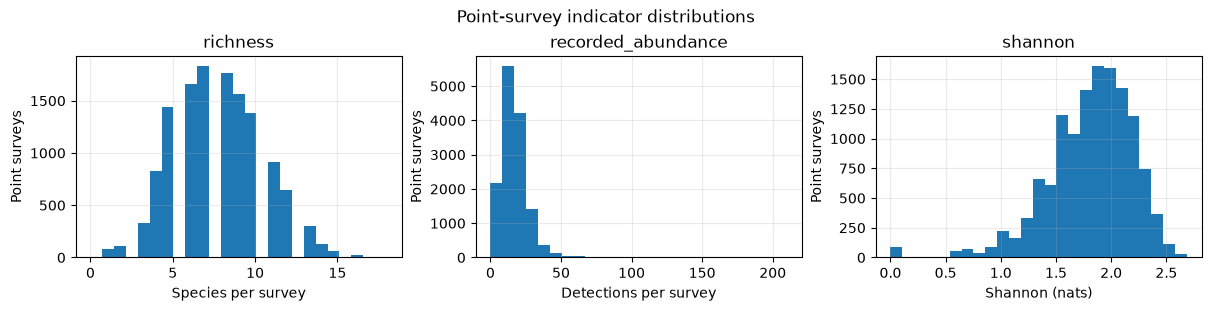

In [11]:
# Flag extreme abundance for inspection, without automatically deleting flocks.
outliers = points.nlargest(10, "recorded_abundance")[
    survey_key + ["year", "habitat", "richness", "recorded_abundance", "shannon"]
    ]
display(outliers)

fig, axes = plt.subplots(1, 3, figsize=(12, 3), layout="constrained")
points[metrics].hist(bins=25, ax=axes)
fig.suptitle("Point-survey indicator distributions")
for ax, label in zip(axes, metric_labels.values()):
    ax.set_xlabel(label)
    ax.set_ylabel("Point surveys")
fig.savefig(FIGURES / "indicator_distributions.png")
plt.show()

## 4. Describe survey effort and conditions

Summaries use point surveys rather than detection rows, so species-rich surveys do not receive extra weight. A route visit is `(route, date, visit)`; fewer than ten recorded points means incomplete in this extract, not necessarily unvisited in the field. Observer labels are only a proxy for individual people.

Weather summaries use the unique nonmissing code within a survey; multiple codes are marked as conflicting. Codes are kept as recorded, without undocumented physical meanings.

In [12]:
route_visits = points.groupby(visit_key)["point"].nunique()
route_visits = route_visits.rename("n_points").reset_index()
route_visits["year"] = route_visits["date"].dt.year
route_visits["incomplete"] = route_visits["n_points"] < 10

effort = points.groupby("year").agg(
    point_surveys=("point", "size"),
    routes=("route_key", "nunique"),
)
effort["observer_labels"] = obs.groupby("year")["observer_key"].nunique()

visit_effort = route_visits.groupby("year").agg(
    route_visits=("n_points", "size"),
    incomplete_visits=("incomplete", "sum"),
)
effort = effort.join(visit_effort).reindex(years)
effort["incomplete_percent"] = 100 * effort["incomplete_visits"] / effort["route_visits"]
points = points.merge(route_visits[visit_key + ["n_points", "incomplete"]], on=visit_key, validate="many_to_one")
display(effort.round(2))

,point_surveys,routes,observer_labels,route_visits,incomplete_visits,incomplete_percent
year,,,,,,
2014,779,41,24,80,4,5.00
2015,1060,53,26,111,8,7.21
2016,1162,59,28,118,4,3.39
2017,1169,60,27,121,7,5.79
2018,1265,64,23,130,7,5.38
2019,1247,64,21,126,3,2.38
2020,1158,63,15,116,1,0.86
2021,1256,63,12,128,6,4.69
2022,1259,63,15,127,3,2.36


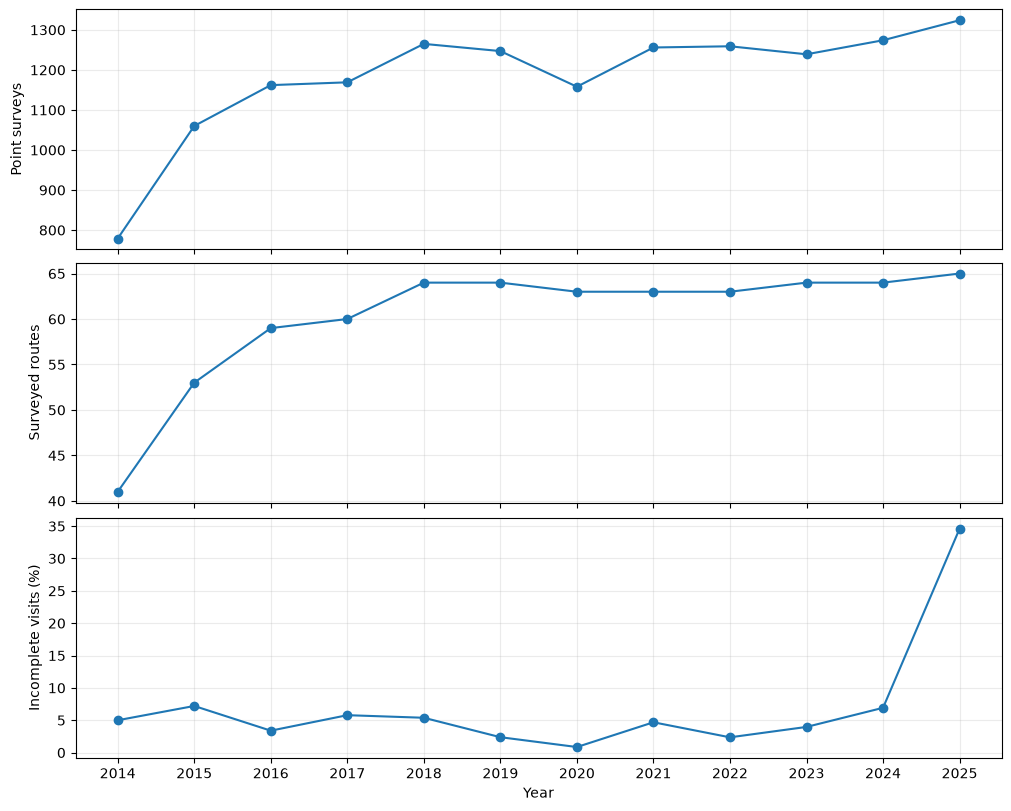

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for ax, field, label in zip(axes, ["point_surveys", "routes", "incomplete_percent"],
                            ["Point surveys", "Surveyed routes", "Incomplete visits (%)"]):
    effort[field].plot(ax=ax, marker="o", ylabel=label)
axes[-1].set(xlabel="Year", xticks=list(years))
fig.savefig(FIGURES / "sampling_effort.png")
plt.show()

In [14]:
dataset_summary = pd.Series({
    "detection_rows": len(obs),
    "point_surveys": len(points),
    "routes": obs["route_key"].nunique(),
    "fixed_route_points": obs[["route_key", "point"]].drop_duplicates().shape[0],
    "observer_labels": obs["observer_key"].nunique(),
    "taxon_labels_including_unresolved_and_RAS": obs["species_key"].nunique(),
    "first_year": obs["year"].min(), "last_year": obs["year"].max(),
}, name="value").to_frame()
display(dataset_summary)

route_effort = points.groupby(["route_key", "year"]).size().unstack("year", fill_value=0)
display(route_effort.describe().loc[["min", "25%", "50%", "75%", "max"]])
habitat_effort = pd.crosstab(points["year"], points["habitat"].fillna("Missing"))
display(habitat_effort)

# Count distinct surveys per observer. Multiple labels on a survey can overlap.
observer_surveys = obs.dropna(subset=["observer_key"]).drop_duplicates(survey_key + ["observer_key"])
observer_workload = observer_surveys.groupby(["year", "observer_key"]).size()
observer_effort = observer_workload.groupby("year").agg(["count", "min", "median", "max"])
observer_effort.columns = ["observer_labels", "min_surveys", "median_surveys", "max_surveys"]
display(observer_effort)

,value
detection_rows,112252
point_surveys,14192
routes,65
fixed_route_points,650
observer_labels,41
taxon_labels_including_unresolved_and_RAS,102
first_year,2014
last_year,2025


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0
25%,0.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0
50%,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0
75%,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0,20.0
max,21.0,21.0,21.0,21.0,24.0,21.0,20.0,21.0,20.0,21.0,21.0,64.0


habitat,Agricole,Forêt humide,Forêt sèche,Mangrove,Plage,Périurbain,Urbain
year,,,,,,,
2014,140,179,220,20,60,140,20
2015,220,241,277,40,61,200,21
2016,239,234,300,60,48,240,41
2017,252,240,297,60,50,230,40
2018,254,260,360,60,60,231,40
2019,237,250,361,60,59,240,40
2020,250,230,278,60,60,240,40
2021,256,261,340,60,59,240,40
2022,260,259,340,60,60,240,40


,observer_labels,min_surveys,median_surveys,max_surveys
year,,,,
2014,24,10,20.0,130
2015,26,10,20.0,208
2016,28,10,30.0,198
2017,27,10,21.0,260
2018,23,10,40.0,430
2019,21,10,39.0,411
2020,15,10,20.0,648
2021,12,19,50.0,735
2022,15,20,40.0,559


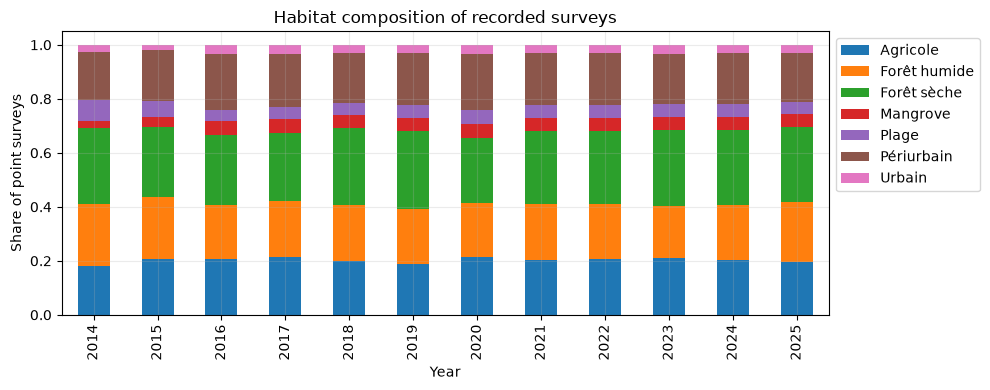

In [15]:
ax = habitat_effort.div(habitat_effort.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(10, 4))
ax.set(xlabel="Year", ylabel="Share of point surveys", title="Habitat composition of recorded surveys")
ax.legend(bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES / "habitat_coverage.png")
plt.show()

In [16]:
weather_fields = ["cloud", "rain", "wind", "visibility"]
weather = obs[survey_key + weather_fields].copy()
for field in weather_fields:
    # Keep source codes categorical; no undocumented meteorological meanings.
    text = weather[field].astype("string").str.strip().replace("", pd.NA)
    weather[field] = text.str.replace(r"\.0$", "", regex=True)
weather_groups = weather.groupby(survey_key)
survey_weather = weather_groups[weather_fields].first()
weather_nunique = weather_groups[weather_fields].nunique()
survey_weather = survey_weather.mask(weather_nunique.gt(1), "Conflicting").fillna("Missing")
survey_weather = survey_weather.reset_index().merge(points[survey_key + ["year"]], on=survey_key, validate="one_to_one")
weather_tables = {
    field: pd.crosstab(survey_weather["year"], survey_weather[field])
    for field in weather_fields
}
for field, table in weather_tables.items():
    print(field)
    display(table)
print(
    "Negative wind codes and rare visibility codes need source verification; they are not used to exclude bird counts.")

# Source-row counts audit codes; these are not survey effort estimates.
weather_code_audit = pd.concat([
    weather[field].value_counts(dropna=False).rename_axis("code").reset_index(name="source_rows").assign(field=field)
    for field in weather_fields
], ignore_index=True)
display(weather_code_audit)

cloud


cloud,1,2,3,Conflicting
year,,,,
2014,319,319,134,7
2015,401,477,177,5
2016,390,495,274,3
2017,237,548,378,6
2018,374,652,237,2
2019,308,638,294,7
2020,249,689,215,5
2021,430,564,258,4
2022,275,632,342,10


rain


rain,1,2,3,Conflicting
year,,,,
2014,752,25,1,1
2015,1021,35,0,4
2016,1109,46,5,2
2017,1110,57,0,2
2018,1216,42,5,2
2019,1192,50,3,2
2020,1144,14,0,0
2021,1226,27,3,0
2022,1205,32,16,6


wind


wind,1,2,3,Conflicting,Missing
year,,,,,
2014,505,239,33,2,0
2015,702,279,68,11,0
2016,798,281,78,2,3
2017,791,278,97,3,0
2018,814,338,110,3,0
2019,833,370,42,2,0
2020,642,447,66,3,0
2021,696,493,63,4,0
2022,656,505,96,2,0


visibility


visibility,1,2,3,Conflicting
year,,,,
2014,691,83,3,2
2015,550,395,114,1
2016,555,490,116,1
2017,326,443,396,4
2018,720,456,87,2
2019,858,321,67,1
2020,981,149,25,3
2021,986,223,44,3
2022,792,421,40,6


Negative wind codes and rare visibility codes need source verification; they are not used to exclude bird counts.


,code,source_rows,field
0,2,57204,cloud
1,1,29217,cloud
2,3,25829,cloud
3,<NA>,2,cloud
4,1,109158,rain
5,2,2919,rain
6,3,174,rain
7,<NA>,1,rain
8,1,71284,wind
9,2,34394,wind


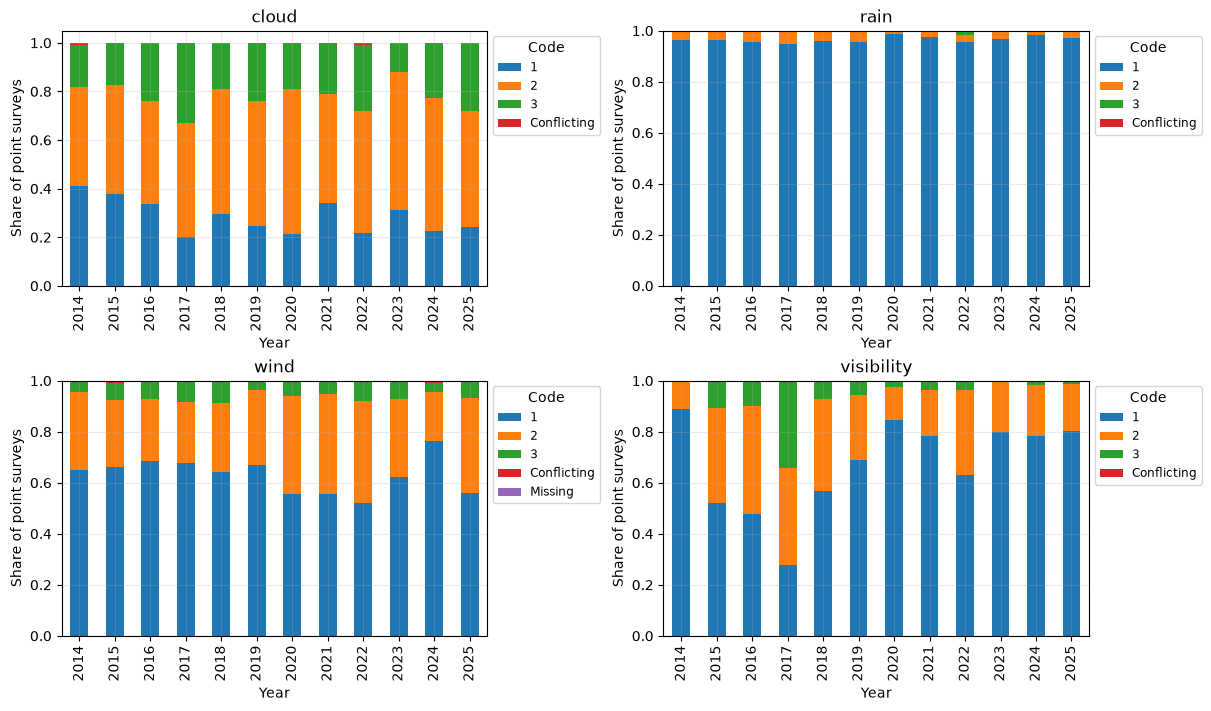

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
for ax, (field, table) in zip(axes.flat, weather_tables.items()):
    table.div(table.sum(axis=1), axis=0).plot.bar(stacked=True, ax=ax, title=field)
    ax.set(xlabel="Year", ylabel="Share of point surveys")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize="small", title="Code")
fig.savefig(FIGURES / "weather_conditions.png")
plt.show()

## 5. Annual indicators

Average valid point surveys within each route/year, then average routes with equal weight. This limits unequal route effort but does not correct imperfect detection or changes within routes. Missing surveys are never inserted as zero. Valid survey and route counts accompany each estimate.

In [18]:
# First average surveys within a route, then average routes within a year.
route_year = points.groupby(["route_key", "year"])[metrics].mean()
annual = route_year.groupby("year").mean().reindex(years)

contributing_routes = route_year.groupby("year")[metrics].count()
valid_surveys = points.groupby("year")[metrics].count()

annual = annual.join(contributing_routes.add_suffix("_routes"))
annual = annual.join(valid_surveys.add_suffix("_valid_surveys"))
display(annual.round(4))

,richness,recorded_abundance,shannon,richness_routes,recorded_abundance_routes,shannon_routes,richness_valid_surveys,recorded_abundance_valid_surveys,shannon_valid_surveys
year,,,,,,,,,
2014,6.4322,14.0114,1.6665,40,40,39,655,740,654
2015,7.3533,16.2893,1.7677,53,53,53,900,1059,900
2016,7.7539,16.5122,1.8299,59,59,59,994,1155,993
2017,7.7253,17.5533,1.8136,60,60,60,1040,1165,1040
2018,7.4403,15.8406,1.7679,64,64,64,1163,1261,1163
2019,7.5680,16.9029,1.7796,64,64,64,1159,1241,1159
2020,8.3918,18.7225,1.8948,63,63,63,1131,1142,1131
2021,8.3256,19.0750,1.8738,63,63,63,1218,1252,1218
2022,8.3034,19.2121,1.8760,63,63,63,1243,1255,1243


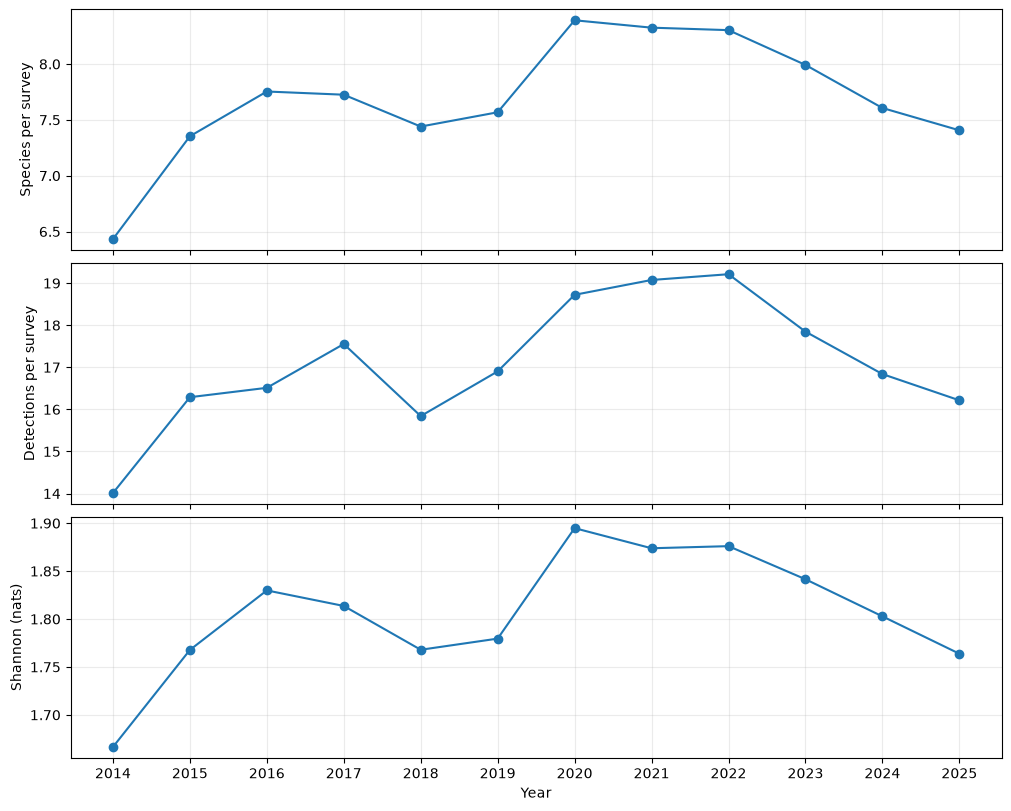

In [19]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for ax, (field, label) in zip(axes, metric_labels.items()):
    annual[field].plot(ax=ax, marker="o", ylabel=label)
axes[-1].set(xlabel="Year", xticks=list(years))
fig.savefig(FIGURES / "annual_indicators.png")
plt.show()

## 6. Sensitivity to preparation and route coverage

Recompute the same annual estimator after excluding ambiguous surveys, incomplete visits, or both. These are alternative inclusion rules, not corrected population estimates. Also hold the route set constant across all twelve years, separately for each indicator. Uncertainty and trend inference belong to Notebook 2.

In [20]:
scenarios = {
    "baseline": pd.Series(True, index=points.index),
    "no_ambiguous_surveys": ~points["metadata_conflict"] & ~points["repeated_species"],
    "complete_visits": ~points["incomplete"],
    "complete_unambiguous": ~points["incomplete"] & ~points["metadata_conflict"] & ~points["repeated_species"],
}
sensitivity_parts = []
for scenario, keep in scenarios.items():
    subset = points.loc[keep]
    route_means = subset.groupby(["route_key", "year"])[metrics].mean()
    for metric in metrics:
        table = route_means[metric].groupby("year").agg(estimate="mean", routes="count")
        table["valid_surveys"] = subset.groupby("year")[metric].count()
        table["indicator"] = metric
        table["scenario"] = scenario
        sensitivity_parts.append(table.reset_index())
sensitivity = pd.concat(sensitivity_parts, ignore_index=True)
sensitivity["baseline"] = [annual.loc[y, m] for y, m in zip(sensitivity["year"], sensitivity["indicator"])]
sensitivity["difference"] = sensitivity["estimate"] - sensitivity["baseline"]
sensitivity_summary = sensitivity.groupby(["scenario", "indicator"]).agg(
    max_absolute_difference=("difference", lambda s: s.abs().max()),
    min_routes=("routes", "min"),
)
display(sensitivity_summary.round(4))
display(sensitivity.loc[sensitivity["year"].eq(2025)].round(4))

max_absolute_difference  min_routes
scenario             indicator                                              
baseline             recorded_abundance                   0.0000          40
                     richness                             0.0000          40
                     shannon                              0.0000          39
complete_unambiguous recorded_abundance                   0.2575          40
                     richness                             0.0780          40
                     shannon                              0.0264          39
complete_visits      recorded_abundance                   0.2467          40
                     richness                             0.0856          40
                     shannon                              0.0272          39
no_ambiguous_surveys recorded_abundance                   0.2041          40
                     richness                             0.0400          40
                     shannon                              0.0041          39

,year,estimate,routes,valid_surveys,indicator,scenario,baseline,difference
11,2025,7.4066,65,1241,richness,baseline,7.4066,0.0000
23,2025,16.2157,65,1323,recorded_abundance,baseline,16.2157,0.0000
35,2025,1.7638,65,1240,shannon,baseline,1.7638,0.0000
47,2025,7.3937,65,1213,richness,no_ambiguous_surveys,7.4066,-0.0128
59,2025,16.1664,65,1291,recorded_abundance,no_ambiguous_surveys,16.2157,-0.0493
71,2025,1.7625,65,1212,shannon,no_ambiguous_surveys,1.7638,-0.0013
83,2025,7.4922,63,1130,richness,complete_visits,7.4066,0.0856
95,2025,15.9690,63,1209,recorded_abundance,complete_visits,16.2157,-0.2467
107,2025,1.7910,63,1130,shannon,complete_visits,1.7638,0.0272
119,2025,7.4845,63,1103,richness,complete_unambiguous,7.4066,0.0780


,balanced_routes,max_absolute_difference
indicator,,
recorded_abundance,39,1.1937
richness,39,0.2535
shannon,38,0.0434


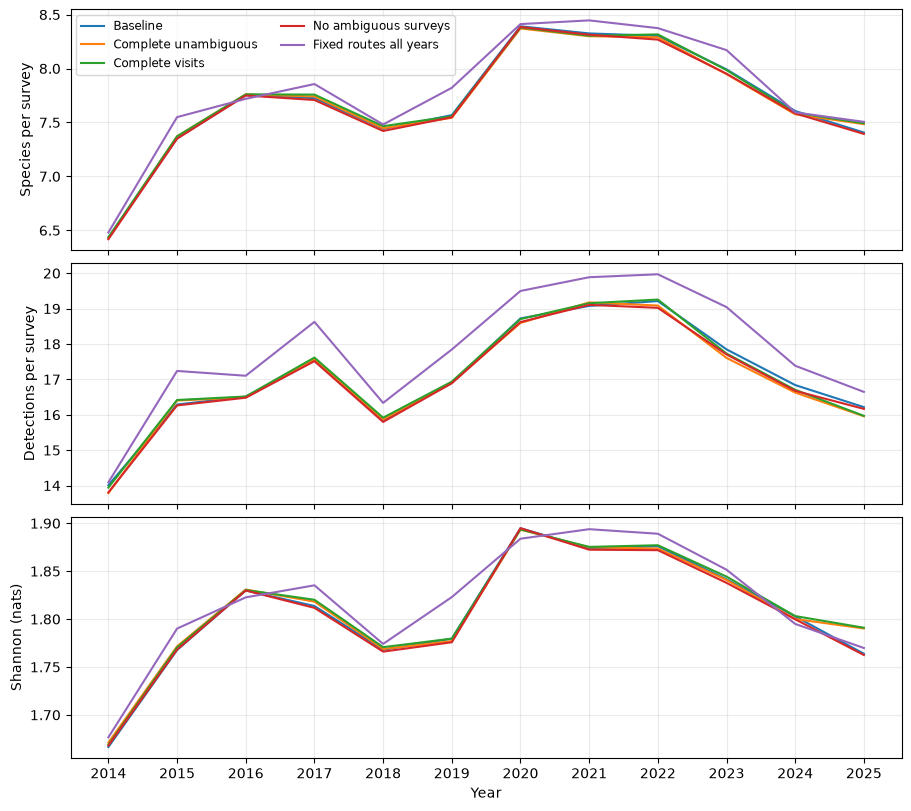

In [21]:
balanced_parts = []
for metric in metrics:
    wide = route_year[metric].unstack("year").reindex(columns=years)
    complete = wide.dropna()
    table = complete.mean().rename("estimate").to_frame()
    table.index.name = "year"
    table["routes"] = len(complete)
    table["indicator"] = metric
    table["baseline"] = annual[metric]
    table["difference"] = table["estimate"] - table["baseline"]
    balanced_parts.append(table.reset_index())
balanced = pd.concat(balanced_parts, ignore_index=True)
display(balanced.groupby("indicator").agg(
    balanced_routes=("routes", "first"),
    max_absolute_difference=("difference", lambda s: s.abs().max()),
).round(4))

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, layout="constrained")
for ax, metric, label in zip(axes, metrics, ["Species per survey", "Detections per survey", "Shannon (nats)"]):
    comparison = sensitivity.loc[sensitivity["indicator"].eq(metric)].pivot(index="year", columns="scenario",
                                                                            values="estimate")
    comparison["fixed_routes_all_years"] = balanced.loc[balanced["indicator"].eq(metric)].set_index("year")["estimate"]
    comparison.rename(columns=lambda s: s.replace("_", " ").capitalize()).plot(ax=ax, ylabel=label, legend=False)
axes[0].legend(fontsize="small", ncol=2)
axes[-1].set(xlabel="Year", xticks=list(years))
fig.savefig(FIGURES / "preparation_sensitivity.png")
plt.show()

## 7. Export and handoff

Notebook 2 reads the same three prepared tables as before. Baseline inclusion rules are retained; sensitivity results are separate. Exports omit observer names, normalized observer labels and comments. Audit tables use aggregate counts only.

Standalone annual and distribution plots are exported here for slides 8–10. All plots use the same notebook defaults and the single `figures/` directory.

In [22]:
# Export analysis data without names or free-text comments.
private_columns = ["observer", "observer_key", "comment"]
observations_export = obs.drop(columns=private_columns)

observations_export.to_csv(
    ROOT / "data/processed/observations_clean.csv",
    index=False,
)
points.to_csv(ROOT / "data/processed/point_surveys.csv", index=False)
route_year.to_csv(ROOT / "data/processed/route_year_indicators.csv")
annual.to_csv(ROOT / "results/annual_indicators.csv")
effort.to_csv(ROOT / "results/annual_sampling_effort.csv")

In [23]:
tables = {
    "sheet_structure": sheet_structure,
    "dataset_summary": dataset_summary,
    "cleaning_audit": cleaning_audit,
    "missingness": missingness,
    "reference_audit": reference_audit,
    "unmatched_species": unmatched_species,
    "quality_by_year": quality_by_year,
    "route_sampling_effort": route_effort,
    "habitat_sampling_effort": habitat_effort,
    "observer_sampling_effort": observer_effort,
    "weather_code_audit": weather_code_audit,
    "largest_recorded_counts": outliers,
    "preparation_sensitivity": sensitivity,
    "balanced_route_sensitivity": balanced,
}
for name, table in tables.items():
    if table.index.name is None:
        table.index.name = "field"
    table.to_csv(ROOT / f"results/{name}.csv", index=name not in {
        "sheet_structure", "weather_code_audit", "largest_recorded_counts", "preparation_sensitivity",
        "balanced_route_sensitivity"
    })
for field, table in weather_tables.items():
    table.to_csv(ROOT / f"results/weather_{field}.csv")
route_visits.to_csv(ROOT / "results/route_visit_completeness.csv", index=False)
print("Prepared tables and descriptive figures exported. Continue with Notebook 2.")

Prepared tables and descriptive figures exported. Continue with Notebook 2.


In [24]:
# Reuse the same notebook style for standalone charts on slides 8–10.
for table, fields in [(annual, metrics), (effort, ["point_surveys", "routes"])]:
    for field in fields:
        ax = table[field].plot(marker="o", figsize=(10, 5), title=field.replace("_", " ").capitalize())
        ax.set(xlabel="Year", ylabel=metric_labels.get(field, "Count"), xticks=list(years))
        ax.figure.savefig(FIGURES / f"{field}.png", bbox_inches="tight")
        plt.close(ax.figure)

for field in metrics[:2]:
    bins = np.arange(-0.5, points[field].max() + 1.5) if field == "richness" else 35
    ax = points[field].dropna().plot.hist(bins=bins, figsize=(10, 5),
                                          title=field.replace("_", " ").capitalize() + " distribution")
    ax.set(xlabel=metric_labels[field], ylabel="Point surveys")
    ax.figure.savefig(FIGURES / f"{field}_distribution.png", bbox_inches="tight")
    plt.close(ax.figure)
print("Standalone slide figures saved in figures/.")

Standalone slide figures saved in figures/.


## Reading the results

Annual curves describe sampled routes. Changes in survey conditions, route coverage and quality exclusions can affect comparisons. The sensitivity tables quantify differences under alternative inclusion rules; they do not eliminate detection bias. Large counts are retained unless internally inconsistent.

Notebook 2 supplies confidence intervals, formal trends and species-level comparisons. Source: Martinique Breeding Bird Monitoring, supplied workbook.